# 1. Explore the local HARTH data — Member 1

HARTH is already available in data/harth/. This notebook reads those CSV files, creates data audits and explores the signals. There is no download or extraction step. Install requirements.txt once and select that environment as the kernel before starting.

Uses the fixed UCI release: 22 people, two accelerometers, six axes at 50 Hz. Acceleration is in g. All 12 labels are retained.

[UCI dataset description](https://archive.ics.uci.edu/dataset/779/harth) · [Authors’ implementation](https://github.com/ntnu-ai-lab/harth-ml-experiments)

These cells have not been executed.

In [1]:
from pathlib import Path
import os
import sys
# Find the project from the workspace, project folder, or notebooks folder.
ROOT = next((p for p in [Path.cwd(), Path.cwd() / 'harth_project', Path.cwd().parent]
             if (p / 'har_utils.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the IMLProj workspace or harth_project folder.')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from har_utils import *

### Audit each participant

Count readings, invalid values and irregular timestamps, then record activity counts. The resulting two tables let us inspect both data quality and label coverage.

In [2]:
def audit_data():
    subjects, counts = [], []
    for path in subject_files():
        frame = read_subject(path)
        dt = frame.timestamp.diff().dt.total_seconds()
        subjects.append({'subject': path.stem, 'rows': len(frame),
                         'missing_sensor_values': int(frame[AXES].isna().sum().sum()),
                         'nonfinite_sensor_values': int((~np.isfinite(frame[AXES])).sum().sum()),
                         'duplicate_timestamps': int(frame.timestamp.duplicated().sum()),
                         'irregular_intervals': int(((dt < .019) | (dt > .021)).sum()),
                         'recorded_minutes': len(frame) / 50 / 60})
        for label, n in frame.label.value_counts().items():
            counts.append({'subject': path.stem, 'label': int(label),
                           'activity': ACTIVITIES[label], 'samples': int(n)})
    return pd.DataFrame(subjects), pd.DataFrame(counts)

## Audit the existing dataset

Read the subject CSV files already in data/harth/. The audit is recomputed when this cell runs. We do not interpolate missing readings or silently reorder timestamps.

In [3]:
(ROOT / 'results').mkdir(exist_ok=True)
record_environment()
audit, counts = audit_data()
audit.to_csv(ROOT / 'results/subject_audit.csv', index=False)
counts.to_csv(ROOT / 'results/class_counts.csv', index=False)
display(audit)
print('Total readings:', audit.rows.sum())

,subject,rows,missing_sensor_values,nonfinite_sensor_values,duplicate_timestamps,irregular_intervals,recorded_minutes
0,S006,408709,0,0,0,408708,136.236333
1,S008,418989,0,0,0,38,139.663000
2,S009,154464,0,0,0,6,51.488000
3,S010,351649,0,0,0,13,117.216333
4,S012,382414,0,0,0,32,127.471333
5,S013,369077,0,0,0,54,123.025667
6,S014,366487,0,0,0,69,122.162333
7,S015,418392,0,0,0,36,139.464000
8,S016,355418,0,0,0,35,118.472667
9,S017,366609,0,0,0,38,122.203000


Total readings: 6461328


In [4]:
example = read_subject(subject_files()[0])
display(example.head())
display(pd.Series(ACTIVITIES, name='activity').rename_axis('label').to_frame())

,timestamp,back_x,back_y,back_z,thigh_x,thigh_y,thigh_z,label
0,2019-01-12 00:00:00.000,-0.760242,0.299570,0.468570,-5.092732,-0.298644,0.709439,6
1,2019-01-12 00:00:00.010,-0.530138,0.281880,0.319987,0.900547,0.286944,0.340309,6
2,2019-01-12 00:00:00.020,-1.170922,0.186353,-0.167010,-0.035442,-0.078423,-0.515212,6
3,2019-01-12 00:00:00.030,-0.648772,0.016579,-0.054284,-1.554248,-0.950978,-0.221140,6
4,2019-01-12 00:00:00.040,-0.355071,-0.051831,-0.113419,-0.547471,0.140903,-0.653782,6


,activity
label,
1,walking
2,running
3,shuffling
4,stairs_up
5,stairs_down
6,standing
7,sitting
8,lying
13,cycling_sit


## Class imbalance and participant coverage

Check whether each activity occurs in every participant. A high accuracy can hide poor recall for rare activities.

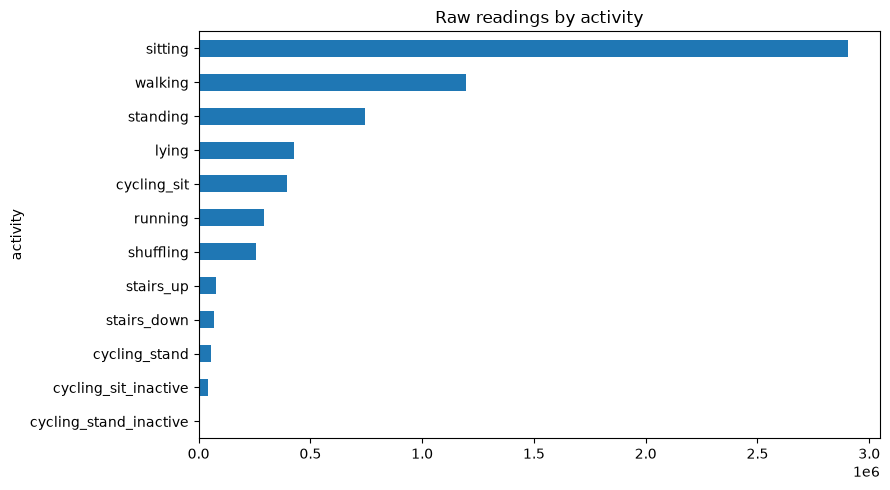

activity,cycling_sit,cycling_sit_inactive,cycling_stand,cycling_stand_inactive,lying,running,shuffling,sitting,stairs_down,stairs_up,standing,walking
subject,,,,,,,,,,,,
S006,25040.0,11290.0,3130.0,0.0,13036.0,0.0,12693.0,253029.0,1550.0,1370.0,62682.0,24889.0
S008,7548.0,170.0,748.0,750.0,0.0,0.0,28827.0,292812.0,750.0,708.0,65222.0,21454.0
S009,120101.0,10375.0,10926.0,120.0,0.0,0.0,178.0,0.0,560.0,448.0,6080.0,5676.0
S010,0.0,0.0,0.0,0.0,0.0,0.0,29738.0,46446.0,3422.0,5958.0,90175.0,175910.0
S012,0.0,0.0,0.0,0.0,18892.0,2198.0,7192.0,311722.0,2772.0,4320.0,22360.0,12958.0
S013,2764.0,100.0,0.0,0.0,7554.0,3494.0,37316.0,223424.0,2846.0,3440.0,53591.0,34548.0
S014,5570.0,0.0,0.0,0.0,9420.0,2490.0,18514.0,236582.0,4428.0,5066.0,56331.0,28086.0
S015,7268.0,0.0,1790.0,0.0,63332.0,2946.0,12000.0,195040.0,6626.0,7066.0,67302.0,55022.0
S016,10474.0,250.0,288.0,0.0,39966.0,2806.0,17008.0,189796.0,2392.0,316.0,52824.0,39298.0


,subjects containing activity
activity,
cycling_stand_inactive,6
cycling_stand,12
cycling_sit_inactive,13
cycling_sit,16
running,17
lying,18
sitting,21
stairs_up,21
shuffling,22


In [5]:
totals = counts.groupby('activity')['samples'].sum().sort_values()
totals.plot.barh(figsize=(9, 5), title='Raw readings by activity')
plt.tight_layout(); plt.show()
coverage = counts.pivot(index='subject', columns='activity', values='samples').fillna(0)
display(coverage)
display((coverage > 0).sum().sort_values().to_frame('subjects containing activity'))

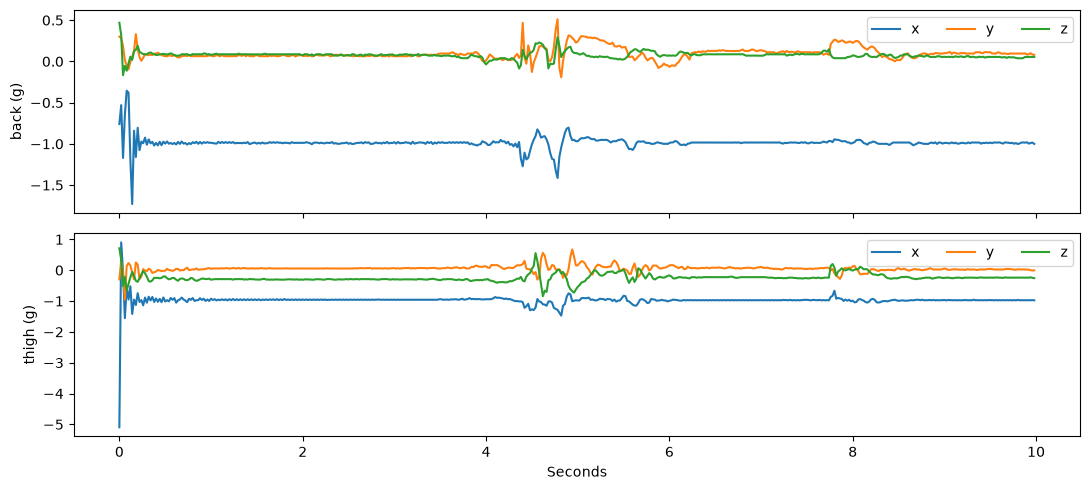

In [6]:
snippet = example.iloc[:500]
t = np.arange(len(snippet)) / 50
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for ax, sensor in zip(axes, ['back', 'thigh']):
    for axis in 'xyz':
        ax.plot(t, snippet[f'{sensor}_{axis}'], label=axis)
    ax.set_ylabel(f'{sensor} (g)'); ax.legend(ncol=3)
axes[-1].set_xlabel('Seconds'); plt.tight_layout(); plt.show()

## Handoff to Member 2

Explain the class balance, participant coverage and timestamp audit. One row is a reading, not a training window. Subject IDs and timestamps are metadata, never predictors.

Notebook 02 reads the same local data/harth subject files. On another machine, copy the data/harth folder and project code. No in-memory variables need to be passed between notebooks.